In [1]:
import os
from pathlib import Path
import pandas as pd
import librosa

import numpy as np
from numpy import ndarray
import random

import matplotlib.pyplot as plt
import glob
from tqdm import tqdm
import pyworld as pw
import pysptk

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

from IPython.display import display, Audio

from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split 
import copy 

from pysptk.synthesis import AllPoleDF
from pysptk.synthesis import Synthesizer

import torch
import torchaudio

import scipy
from scipy.stats import skew, kurtosis
import scipy.fft
import scipy.signal as signal

/home/smg/v-viola/miniconda3/envs/moe_env/lib/python3.12/site-packages/pyworld/__init__.py:13: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [12]:
import math

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Define the model part using lazypredict


In [3]:
def classifing_lazypredict(data_train, data_test, feat_names, label_name):

    clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    X_train = data_train[feat_names].to_numpy()
    X_test = data_test[feat_names].to_numpy()
    y_train = data_train[label_name].to_numpy()
    y_test = data_test[label_name].to_numpy()
    _, metrics = clf.fit(X_train, X_test, y_train, y_test);
    
    model_dictionary = clf.provide_models(X_train, X_test, y_train, y_test)
    return model_dictionary, metrics

# Common functions

## Data I/O

In [4]:
def load_audio(path, trim=True, normalize=True, sr=16000, top_db=40):
    
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    # Resample if necessary
    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)

    # Normalize waveform
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    # Trim leading and trailing silence
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze(), sr    


def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    # --- repeat signal if too short ---
    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        # --- random crop (training mode) ---
        last_valid_start_sample = x_len - max_len

        if last_valid_start_sample != 0:
            start_sample = random.randrange(0, last_valid_start_sample)
        else:
            start_sample = 0

        x_pad = x[start_sample : start_sample + max_len]

    else:
        # --- deterministic middle crop (evaluation mode) ---
        num_windows = round(x_len / max_len)

        if num_windows % 2 == 1:  # odd number of windows
            middle = num_windows // 2
        else:  # even number of windows
            middle = (num_windows // 2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample : start_sample + max_len]

    return x_pad


class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()

## Feature Extraction

In [5]:
def feat_pipeline(file_list, mod_extraction, mod_manipulation, feat_name, debug=None):

    rows = []
    total = len(file_list)
        
    for cnt, i in tqdm(enumerate(file_list), total=len(file_list)):
        x, sr = load_audio(i, trim=True, normalize=True)
        
        #x = torch.tensor(x)
        #x = prepare_audio_window(x, is_eval=True)
        #x = x.numpy()
        
        feat = mod_extraction(x)

        if mod_manipulation is not None:
            feat = mod_manipulation(feat)
           
        rows.append({
            "name": str(i.name),
            "{:s}".format(feat_name): feat,
        })
    
        if debug is not None and cnt >= debug:
            break
            
    dataframe = pd.DataFrame(rows)
    return dataframe

# Energy Inconsistency

## Extraction

In [82]:
def apply_db(spec):
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )
    return spec_db

def spec_extraction(y, stft_params):
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )

    spec = spec_transform(torch.Tensor(y).unsqueeze(0))
    spec = spec.squeeze(0)

    spec_db = apply_db(spec)

    return spec

## Manipulation

In [83]:
def spec_manipulation(y, stft_params):
    y = torch.tensor(y).float()
    n_samples = y.shape[-1] if y.dim() > 1 else y.shape[0]

    spec_dummy = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )(y.unsqueeze(0))  # just to get n_time
    n_time = spec_dummy.shape[-1]
    width = random.randint(6, 30)

    start_idx = random.randint(0, max(n_time - width, 0))
    end_idx = start_idx + width
    end_idx = min(end_idx, n_time)

    hop_length = stft_params.hop_size
    fft_size = stft_params.fft_size

    start_sample = start_idx * hop_length
    end_sample = min(n_samples, (end_idx - 1) * hop_length + fft_size)

    y_zeroed = y.clone()

    attenuation = random.uniform(0.0, math.sqrt(0.5))
    y_zeroed[start_sample:end_sample] *= attenuation

    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=fft_size,
        hop_length=hop_length,
        power=2
    )
    spec = spec_transform(y_zeroed.unsqueeze(0)).squeeze(0)
    spec_db = apply_db(spec)

    return spec

In [17]:
stft_params = STFTWindowParams()

In [10]:
p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt"
f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"

df = pd.read_csv(p, sep=" ", header=None, names=["speaker_id", "audio_file", "-", "system_id", "key"])

bonafide_df = df[df['key'] == "bonafide"]
row = bonafide_df.iloc[0]      
audio_path = f + "/" + row.audio_file + ".flac"

In [22]:
y, sr = librosa.load(audio_path, sr=16000) 
spec_db, spec = spec_extraction(y, stft_params)
spec_db_manip, spec_manip = spec_manipulation(y, stft_params)

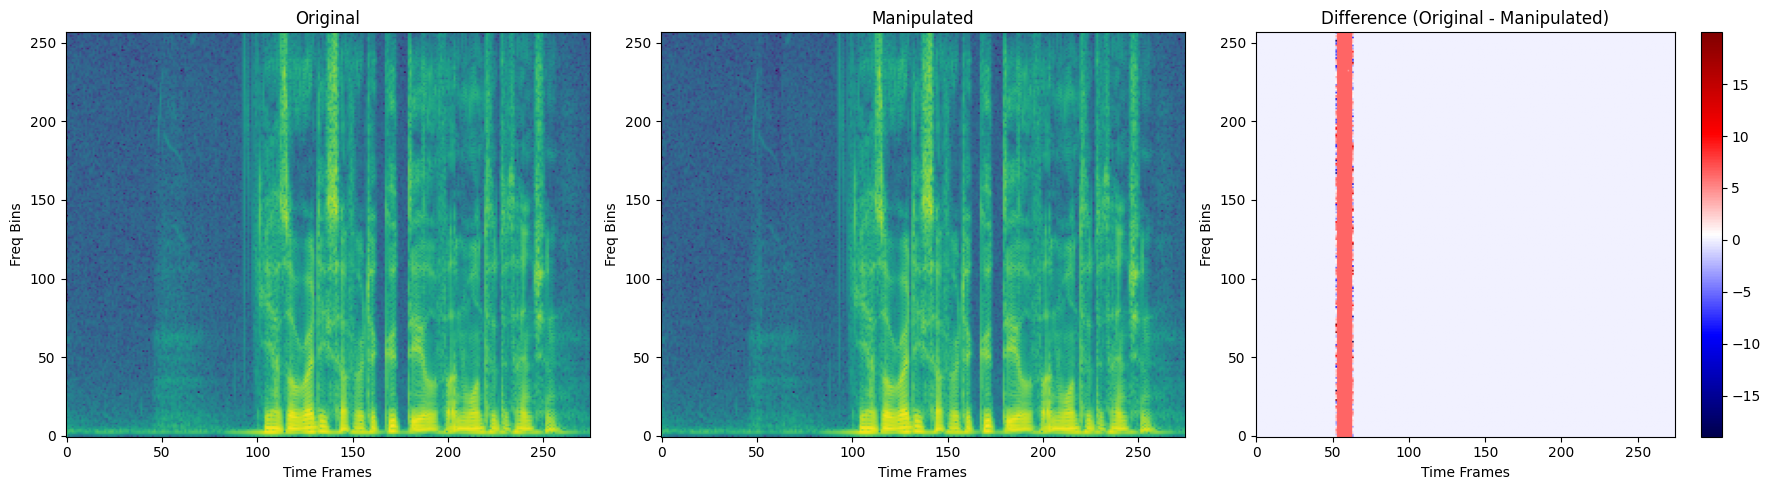

In [23]:
diff = spec_db.numpy() - spec_db_manip.numpy()

plt.figure(figsize=(18, 5))

# Original
plt.subplot(1, 3, 1)
plt.imshow(spec_db.numpy(), origin="lower", aspect="auto")
plt.title("Original")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

# Manipulated
plt.subplot(1, 3, 2)
plt.imshow(spec_db_manip.numpy(), origin="lower", aspect="auto")
plt.title("Manipulated")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

# Difference
plt.subplot(1, 3, 3)
plt.imshow(diff, origin="lower", aspect="auto", cmap="seismic")
plt.title("Difference (Original - Manipulated)")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")
plt.colorbar()

plt.tight_layout()
plt.show()

## Preprocessing

In [66]:
def preprocessing_energy(spec):
    energy = spec.mean(dim=0)
    delta = energy[1:] - energy[:-1]
    
    energy_db = apply_db(energy)
    
    comb = torch.cat([
        energy,
        delta
    ])

    return energy, energy_db, comb

In [37]:
feat, feat_db, feat_comb = preprocessing_energy(spec)
feat_manip, feat_manip_db, feat_manip_comb = preprocessing_energy(spec_manip)

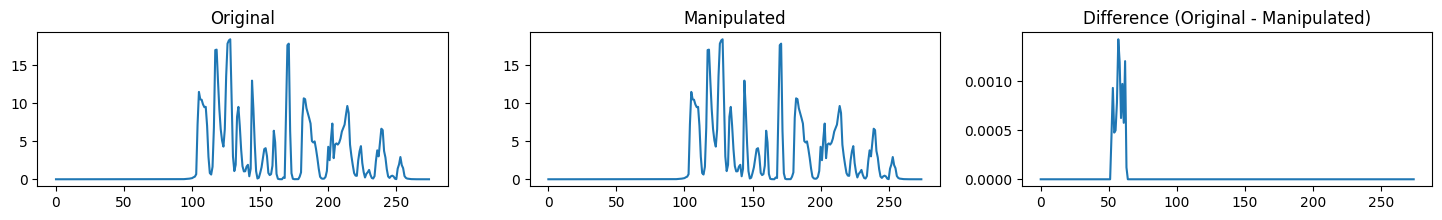

In [32]:
plt.figure(figsize=(18, 2))

# Original
plt.subplot(1, 3, 1)
plt.plot(feat.numpy())
plt.title("Original")

# Manipulated
plt.subplot(1, 3, 2)
plt.plot(feat_manip.numpy())
plt.title("Manipulated")

# Difference
plt.subplot(1, 3, 3)
plt.plot(feat.numpy() - feat_manip.numpy())
plt.title("Difference (Original - Manipulated)")

plt.show()

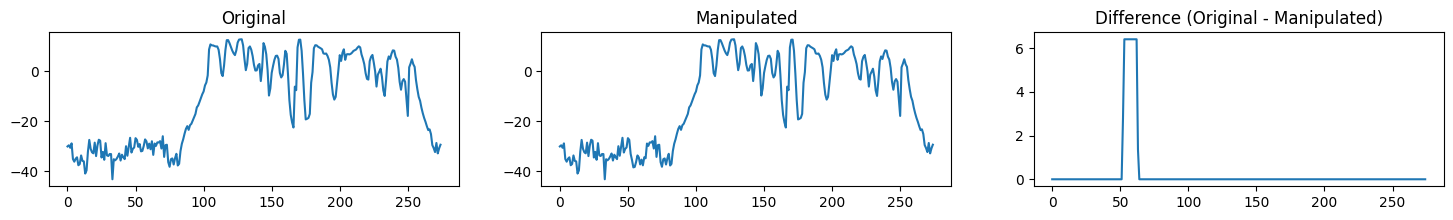

In [38]:
plt.figure(figsize=(18, 2))

# Original
plt.subplot(1, 3, 1)
plt.plot(feat_db.numpy())
plt.title("Original")

# Manipulated
plt.subplot(1, 3, 2)
plt.plot(feat_manip_db.numpy())
plt.title("Manipulated")

# Difference
plt.subplot(1, 3, 3)
plt.plot(feat_db.numpy() - feat_manip_db.numpy())
plt.title("Difference (Original - Manipulated)")

plt.show()

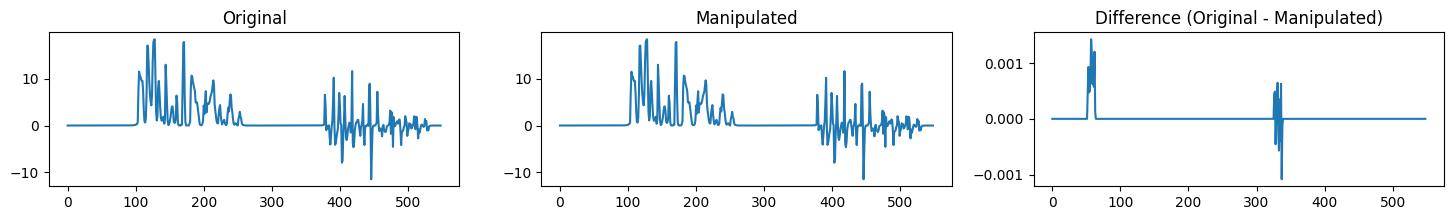

In [39]:
plt.figure(figsize=(18, 2))

# Original
plt.subplot(1, 3, 1)
plt.plot(feat_comb.numpy())
plt.title("Original")

# Manipulated
plt.subplot(1, 3, 2)
plt.plot(feat_manip_comb.numpy())
plt.title("Manipulated")

# Difference
plt.subplot(1, 3, 3)
plt.plot(feat_comb.numpy() - feat_manip_comb.numpy())
plt.title("Difference (Original - Manipulated)")

plt.show()

## Demo

In [93]:
def feat_pipeline_energy(file_list, mod_function, debug=None):

    rows = []
    total = len(file_list)
        
    for cnt, i in tqdm(enumerate(file_list), total=len(file_list)):
        x, sr = load_audio(i, trim=True, normalize=True)
        
        feat = mod_function(x, stft_params)
        feat, _, _ = preprocessing_energy(feat)
           
        rows.append({
            "name": str(i.name),
            "{:s}".format('energy'): feat,
        })
    
        if debug is not None and cnt >= debug:
            break
            
    dataframe = pd.DataFrame(rows)
    return dataframe

In [85]:
p = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
f = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

df_all = pd.read_csv(p, sep=' ', header=None)

# real data
df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
real_list = df_real['path'].tolist()

# actual fake data
df_fake = (
    df_all[df_all[3] == 'A03']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
fake_list = df_fake['path'].tolist()

In [94]:
# sample number 
sample_num = 100

real_dataframe = feat_pipeline_energy(real_list, spec_extraction, debug=sample_num)
fake_dataframe = feat_pipeline_energy(fake_list, spec_extraction, debug=sample_num)
mod_dataframe = feat_pipeline_energy(real_list, spec_manipulation, debug=sample_num)

  4%|██▋                                                                   | 100/2580 [00:00<00:14, 170.57it/s]


In [97]:
mod_dataframe.head(2)

,name,energy
0,LA_T_1138215.flac,"[tensor(0.0263), tensor(0.6807), tensor(7.6473..."
1,LA_T_1271820.flac,"[tensor(0.0058), tensor(7.8460e-05), tensor(4...."


### Proxy feat

In [98]:
def scalar_features(
    energy,
    feature_set=None,
    max_lag=50,
    include_delta=True,
):
    if feature_set is None:
        feature_set = ["std", "ac_decay", "d_std", "d_mean_abs",  "d_max_abs", "d_p95", "d_outlier_ratio", "dd_std", "dyn_ratio", "curv_ratio"]

    def autocorr_decay(x):
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode='full')
        ac = ac[len(ac)//2:]
        ac /= ac[0] + 1e-8
        return np.mean(ac[1:max_lag])

    energy = np.asarray(energy, dtype=float)

    if len(energy) < 5:
        return None

    feats = {}

    d = np.diff(energy)
    dd = np.diff(d)
    feats["std"]   = np.std(energy)
    feats["d_std"] = np.std(d)
    
    if "ac_decay" in feature_set:
        feats["ac_decay"] = autocorr_decay(energy)

    if "d_mean_abs" in feature_set:
        feats["d_mean_abs"] = np.mean(np.abs(d))

    if "d_max_abs" in feature_set:
        feats["d_max_abs"] = np.max(np.abs(d))

    if "d_p95" in feature_set:
        feats["d_p95"] = np.percentile(np.abs(d), 95)

    if "d_outlier_ratio" in feature_set:
        thr = np.median(np.abs(d)) * 3
        feats["d_outlier_ratio"] = np.mean(np.abs(d) > thr)

    if "dd_std" in feature_set:
        feats["dd_std"] = np.std(dd)
    
    if "dyn_ratio" in feature_set:
        feats["dyn_ratio"]  = feats["d_std"] / feats["std"]     

    if "curv_ratio" in feature_set:    
        feats["curv_ratio"] = feats["dd_std"] / feats["d_std"]   
    
    return feats

def make_feature_fn(feature_set, max_lag, include_delta):
    def feature_fn(energy):
        return scalar_features(
            energy,
            feature_set=feature_set,
            max_lag=max_lag,
            include_delta=include_delta
        )
    return feature_fn

def proxy_energy(data_frames, feature_fn):

    df = data_frames.copy()

    feature_dicts = df["energy"].apply(feature_fn)

    feature_df = feature_dicts.apply(
        lambda x: pd.Series(x) if x is not None else pd.Series(dtype=float)
    )

    df = pd.concat([df, feature_df], axis=1)
    feature_names = list(feature_df.columns)

    return df, feature_names

In [101]:
feature_fn = make_feature_fn(
    feature_set=None,
    max_lag=50,
    include_delta=True
)

data_real, feat_names = proxy_energy(real_dataframe, feature_fn)
data_fake, _ = proxy_energy(fake_dataframe, feature_fn)
data_mod,  _ = proxy_energy(mod_dataframe, feature_fn)

data_real['label'] = 1
data_fake['label'] = 0
data_mod['label'] = 0

label_name = 'label'

In [102]:
data_real_train, data_real_test = train_test_split(data_real, test_size=0.5, random_state=123)
data_train = pd.concat([data_real_train, data_mod], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

model_dictionary, metrics = classifing_lazypredict(data_train, data_test, feat_names, label_name)

  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 50, number of negative: 101
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000623 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 512
[LightGBM] [Info] Number of data points in the train set: 151, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.331126 -> initscore=-0.703098
[LightGBM] [Info] Start training from score -0.703098
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [103]:
metrics

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
NearestCentroid,0.68,0.62,0.62,0.67,0.02
BernoulliNB,0.68,0.60,0.60,0.66,0.02
GaussianNB,0.70,0.59,0.59,0.66,0.02
PassiveAggressiveClassifier,0.51,0.56,0.56,0.52,0.02
SVC,0.66,0.50,0.50,0.53,0.02
DummyClassifier,0.66,0.50,0.50,0.53,0.01
CalibratedClassifierCV,0.65,0.49,0.49,0.52,0.11
QuadraticDiscriminantAnalysis,0.60,0.48,0.48,0.54,0.02
AdaBoostClassifier,0.59,0.47,0.47,0.54,0.24


# Fundamental frequency (F0)

## F0 Inconsistency / Monotonic Pitch
**Target system**: Concatenative TTS / some TTS that flatten pitch  
**Feature**: F0 trajectory  
**Manipulations**:  
  
- F0 segment shifting (Incons.)  
- F0 segment shuffling (Incons.)  
- F0 flattening (Monot.)  

### Extraction

In [6]:
def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )

    # pyworld_analysis
    #x = np.array(x, dtype=np.float64)
    #_f0, t = pw.dio(x, sr)    # raw pitch extractor
    #f0_freqs = pw.stonemask(x, _f0, t, sr)  # pitch refinement
    
    return f0_freqs

### Manipulation

In [7]:
def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.87, 0.92),
                    random.uniform(1.08, 1.3)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]
            
    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start + L] = seg[:L]
    
    return f0_mod        


def flatten_f0(f0_traj, strength=0.5, dyn_strength=0.0):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    # global range compression 
    f0_ref = np.nanmedian(f0_mod)

    f0_mod[voiced] = (
        (1.0 - strength) * f0_mod[voiced]
        + strength * f0_ref
    )

    # damp slopes too 
    if dyn_strength > 0:
        f0_smooth = np.copy(f0_mod)

        # simple 3-frame local average
        f0_smooth[1:-1] = (
            f0_mod[:-2] + f0_mod[1:-1] + f0_mod[2:]
        ) / 3.0

        # blend original with smoothed
        f0_mod[voiced] = (
            (1.0 - dyn_strength) * f0_mod[voiced]
            + dyn_strength * f0_smooth[voiced]
        )

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.2, 0.5)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )

    elif mod == 'inc':
        seg_len = random.uniform(0.08, 0.16)

        # Random params for shift
        p_seg = random.uniform(0.4, 0.7)
        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        # Random params for shuffle
        p_shuffle = random.uniform(0.2, 0.5)
        f0_traj_mod = f0_segment_shuffle(
            f0_traj_mod,  # apply on shifted result
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )
        
    elif mod == 'flat':
        f0_traj_mod = flatten_f0(
            f0_traj,
            strength=0.4,
            dyn_strength=0.4
        )
        
    else:
        f0_traj_mod = None
        print("Manipulation not recognized.")
        
    return f0_traj_mod

### Case study

In [8]:
# ======================
# DATA CONFIG
# ======================

protocol_path = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
audio_root = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

#target_algorithm = 'A04'    # ref for concat TTS
target_algorithm = 'A02'   # ref for flat pitch

sample_num = 500

stft_params = STFTWindowParams()

In [9]:
def load_asvspoof_lists(protocol_path, audio_root, target_algorithm):
    
    df_all = pd.read_csv(protocol_path, sep=' ', header=None)

    # FAKE (specific algorithm)
    df_fake = (
        df_all[df_all[3] == target_algorithm]
        .assign(path=lambda df: df[1].apply(
            lambda x: Path(audio_root) / f"{x}.flac"
        ))[['path']]
    )
    fake_list = df_fake['path'].tolist()

    # REAL (bonafide)
    df_real = (
        df_all[df_all[4] == 'bonafide']
        .assign(path=lambda df: df[1].apply(
            lambda x: Path(audio_root) / f"{x}.flac"
        ))[['path']]
    )
    real_list = df_real['path'].tolist()

    return real_list, fake_list


real_list, fake_list = load_asvspoof_lists(
    protocol_path,
    audio_root,
    target_algorithm
)

print("Real:", len(real_list))
print("Fake:", len(fake_list))


Real: 2580
Fake: 3800


In [10]:
# WRAPPERS:

def f0_extraction(wav, stft_params=stft_params):
    f0_traj = extract_f0(
        wav,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )
    return f0_traj

def f0_manipulation(f0_traj, mode=None, stft_params=stft_params):
    if mode is None:
        return f0_traj

    return apply_f0_mod(
        f0_traj,
        mod=mode,
        hop_s=stft_params.hop_sec
    )

In [11]:
def build_dataset(
    real_list,
    fake_list,
    negative_mode=('inc',),
    feat_name='f0',
    sample_num=None
):
    # REAL (positive class)
    real_df = feat_pipeline(
        real_list,
        f0_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    real_df['label'] = 0

    # PROXY NEGATIVES (manipulated real)
    proxy_dfs = []
       
    for mode in negative_mode:
        df_mod = feat_pipeline(
            real_list,
            f0_extraction,
            lambda f0, m=mode: f0_manipulation(f0, m),
            feat_name=feat_name,
            debug=sample_num
        )
        df_mod['label'] = 1
        df_mod['proxy_type'] = mode
        proxy_dfs.append(df_mod)

    proxy_df = pd.concat(proxy_dfs, axis=0)
    
    # TRUE FAKE (evaluation only)
    fake_df = feat_pipeline(
        fake_list,
        f0_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    fake_df['label'] = 1
    fake_df['proxy_type'] = 'real_fake'

    return real_df, proxy_df, fake_df


In [12]:
def f0_scalar_features(
    f0,
    feature_set=None,
    max_lag=50,
    include_delta=True,
):
    if feature_set is None:
        feature_set = ["f0_std", "f0_ac_decay", "df0_std", "df0_mean_abs",  "df0_max_abs", "df0_p95", "df0_outlier_ratio", "ddf0_std", "dyn_ratio", "curv_ratio"]

    def autocorr_decay(x):
        x = x - np.mean(x)
        ac = np.correlate(x, x, mode='full')
        ac = ac[len(ac)//2:]
        ac /= ac[0] + 1e-8
        return np.mean(ac[1:max_lag])

    f0 = np.asarray(f0, dtype=float)
    voiced = ~np.isnan(f0)
    f0v = f0[voiced]

    if len(f0v) < 5:
        return None

    feats = {}

    df0 = np.diff(f0v)
    ddf0 = np.diff(df0)
    feats["f0_std"]   = np.std(f0v)
    feats["df0_std"] = np.std(df0)
    
    if "f0_ac_decay" in feature_set:
        feats["f0_ac_decay"] = autocorr_decay(f0v)

    if "df0_mean_abs" in feature_set:
        feats["df0_mean_abs"] = np.mean(np.abs(df0))

    if "df0_max_abs" in feature_set:
        feats["df0_max_abs"] = np.max(np.abs(df0))

    if "df0_p95" in feature_set:
        feats["df0_p95"] = np.percentile(np.abs(df0), 95)

    if "df0_outlier_ratio" in feature_set:
        thr = np.median(np.abs(df0)) * 3
        feats["df0_outlier_ratio"] = np.mean(np.abs(df0) > thr)

    if "ddf0_std" in feature_set:
        feats["ddf0_std"] = np.std(ddf0)
    
    if "dyn_ratio" in feature_set:
        feats["dyn_ratio"]  = feats["df0_std"] / feats["f0_std"]     

    if "curv_ratio" in feature_set:    
        feats["curv_ratio"] = feats["ddf0_std"] / feats["df0_std"]   
    
    return feats

def make_feature_fn(feature_set, max_lag, include_delta):
    def feature_fn(f0):
        return f0_scalar_features(
            f0,
            feature_set=feature_set,
            max_lag=max_lag,
            include_delta=include_delta
        )
    return feature_fn

In [13]:
def preprocessing(data_frames, feature_fn):

    df = data_frames.copy()

    feature_dicts = df["f0"].apply(feature_fn)

    feature_df = feature_dicts.apply(
        lambda x: pd.Series(x) if x is not None else pd.Series(dtype=float)
    )

    df = pd.concat([df, feature_df], axis=1)
    feature_names = list(feature_df.columns)

    return df, feature_names


In [14]:
# Build raw F0 datasets
real_df, proxy_df, fake_df = build_dataset(
    real_list,
    fake_list,
    #negative_mode=('inc',),   # do not forget the comma at the end
    negative_mode=('flat',),  
    sample_num=sample_num
)

# Define scalar proxy configuration
feature_fn = make_feature_fn(
    #feature_set=["df0_std", "df0_mean_abs", "df0_max_abs", "f0_ac_decay", "ddf0_std", "dyn_ratio"],    # for flat pitch
    #feature_set=["dyn_ratio", "df0_p95", "df0_outlier_ratio", "ddf0_std"],                             # for inconsistency
    feature_set=None,
    max_lag=50,
    include_delta=True
)

# Apply scalar extraction
data_real, feat_names = preprocessing(real_df, feature_fn)
data_proxy, _ = preprocessing(proxy_df, feature_fn)
data_fake, _ = preprocessing(fake_df, feature_fn)


data_real_train, data_real_test = train_test_split(
    data_real,
    test_size=0.5,
    random_state=SEED
)
data_train = pd.concat([data_real_train, data_proxy], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)


model_dictionary, metrics = classifing_lazypredict(
    data_train,
    data_test,
    feat_names,
    'label'
)

 13%|████████▊                                                          | 500/3800 [02:31<16:41,  3.30it/s]


  0%|          | 0/32 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 501, number of negative: 250
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000130 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2458
[LightGBM] [Info] Number of data points in the train set: 751, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.667111 -> initscore=0.695145
[LightGBM] [Info] Start training from score 0.695145
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

In [15]:
metrics

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Time Taken
Model,,,,,
BernoulliNB,0.75,0.74,0.74,0.75,0.02
AdaBoostClassifier,0.78,0.73,0.73,0.77,0.18
PassiveAggressiveClassifier,0.80,0.73,0.73,0.79,0.02
KNeighborsClassifier,0.75,0.72,0.72,0.75,0.02
RidgeClassifier,0.76,0.69,0.69,0.75,0.02
RidgeClassifierCV,0.75,0.69,0.69,0.74,0.02
LinearDiscriminantAnalysis,0.75,0.68,0.68,0.74,0.02
LinearSVC,0.74,0.68,0.68,0.73,0.02
NuSVC,0.74,0.68,0.68,0.73,0.05


# Spectral domain

## Oversmoothing

### Extraction

In [ ]:
def get_lsf(waveform, order=10, frame_length=400, hop_length=160):
    # Ensure waveform is float64 (standard for SPTK C-wrappers)
    waveform = waveform.astype(np.float64)
    
    # 1. Framing
    # Instead of util.frame, we'll use a list comprehension for reliability
    frames = [waveform[i:i + frame_length] for i in range(0, len(waveform) - frame_length, hop_length)]
    frames = np.stack(frames)
    
    # 2. Scipy Windowing
    # 'blackman' is standard, but 'hamming' or 'hann' are also common
    window = signal.get_window('blackman', frame_length, fftbins=False)
    windowed_frames = frames * window
    

    # 3. LPC Analysis
    # Note: lpc returns (order + 1) coefficients
    lpc_coeffs = pysptk.lpc(windowed_frames, order)

    # 4. Convert LPC to LSF
    try:
        # 2. Attempt conversion
        lsf = pysptk.lpc2lsp(lpc_coeffs)
        return lsf
    except RuntimeError:
        # 3. Fallback: If it fails, the filter was likely unstable.
        # We can 'stabilize' it by slightly moving roots inside the circle
        # (Often called bandwidth expansion)
        gamma = 0.9
        lpc_stable = lpc_coeffs * (gamma ** np.arange(lpc_coeffs.shape[1]))
        return pysptk.lpc2lsp(lpc_stable)
        
    return lsf

### Manipulation

In [ ]:
def apply_lsf_mod(lsf, sigma=2.0):
    # We apply the filter along axis 0 (the temporal/frame axis)
    # This blurs the transition of each individual LSF over time
    smoothed_lsf = scipy.ndimage.gaussian_filter1d(lsf, sigma=sigma, axis=0)
    
    # Ensure the LSF ordering property is maintained (stability)
    # LSFs must be strictly increasing: 0 < w1 < w2 ... < pi
    smoothed_lsf = np.sort(smoothed_lsf, axis=1)
    
    return smoothed_lsf

### Case study

In [ ]:
# WRAPPERS:

def lsf_extraction(wav, lsf_order=20, stft_params=stft_params):
    lsf_traj = get_lsf(
            wav + 1e-6 * np.random.randn(len(wav)),
            order= lsf_order,
            frame_length=stft_params.win_size, 
            hop_length=stft_params.hop_size     
        )
    
    return lsf_traj

def lsf_manipulation_smoothing(lsf_traj, stft_params=stft_params):
    return apply_lsf_mod(lsf_traj)

In [ ]:
def build_lsf_dataset(
    real_list,
    fake_list,
    negative_modes=('smoothing',),
    feat_name='lsf',
    sample_num=None
):
    """
    negative_modes: list/tuple of manipulations to apply to REAL data
    """

    # ---- REAL (positive class) ----
    real_df = feat_pipeline(
        real_list,
        lsf_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    real_df['label'] = 1

    # ---- PROXY NEGATIVES ----
    proxy_dfs = []
    for mode in negative_modes:
        if mode == 'smoothing':  # extendable to other LSF manipulations
            mod_fn = lsf_manipulation_smoothing
        else:
            raise ValueError(f"Unknown LSF manipulation: {mode}")

        df_mod = feat_pipeline(
            real_list,
            lsf_extraction,
            mod_fn,
            feat_name=feat_name,
            debug=sample_num
        )
        df_mod['label'] = 0
        df_mod['proxy_type'] = mode
        proxy_dfs.append(df_mod)

    proxy_df = pd.concat(proxy_dfs, axis=0)

    # ---- TRUE FAKE ----
    fake_df = feat_pipeline(
        fake_list,
        lsf_extraction,
        None,
        feat_name=feat_name,
        debug=sample_num
    )
    fake_df['label'] = 0
    fake_df['proxy_type'] = 'real_fake'

    return real_df, proxy_df, fake_df


In [ ]:
def preprocessing_lsf(data_frames, feat_name='lsf'):
    """
    Compute variance per LSF dimension
    """
    df = data_frames.copy()
    order = df.iloc[0][feat_name].shape[1]
    feat_names = []

    for i in range(order):
        col = f'lsp_gv_{i}'
        feat_names.append(col)
        df[col] = df[feat_name].apply(lambda x: x[:, i].std())

    return df, feat_names


In [ ]:
sample_num = 100

# Build LSF datasets
real_df, proxy_df, fake_df = build_lsf_dataset(
    real_list,
    fake_list,
    negative_modes=('smoothing',),  # can add more manipulations here
    sample_num=sample_num
)

# Preprocess: compute variance features
data_real, feat_names = preprocessing_lsf(real_df)
data_proxy, _ = preprocessing_lsf(proxy_df)
data_fake, _ = preprocessing_lsf(fake_df)


In [ ]:
# Split REAL
data_real_train, data_real_test = train_test_split(
    data_real,
    test_size=0.5,
    random_state=SEED
)

# Build train/test
data_train = pd.concat([data_real_train, data_proxy], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

# Train
model_dictionary, metrics = classifing_lazypredict(
    data_train,
    data_test,
    feat_names,
    'label'
)


In [ ]:
metrics


## Perfect silence

In [ ]:
stft_params = STFTWindowParams()

In [ ]:
def apply_db(spec):
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0,
        amin=1e-10,
        db_multiplier=0
    )
    return spec_db

### Extraction

In [ ]:
def spec_extraction(y, stft_params=stft_params):

    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )
    
    spec = spec_transform(torch.Tensor(y).unsqueeze(0))
    spec = spec.squeeze(0)

    spec_db = apply_db(spec)
    
    return spec_db

### Manipulation

In [ ]:
def spec_manipulation(y, stft_params):
    """
    Compute a spectrogram from waveform y and zero out a time region directly in the waveform.
    90% of the time zeroing is at the end, 10% anywhere.
    """
    y = torch.tensor(y).float()
    n_samples = y.shape[-1] if y.dim() > 1 else y.shape[0]

    # Select time frames to zero
    spec_dummy = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )(y.unsqueeze(0))  # just to get n_time
    n_time = spec_dummy.shape[-1]
    width = random.randint(10, 50)

    if random.random() < 0.9:
        # 90% at the end
        start_idx = max(n_time - width - random.randint(0, 5), 0)
    else:
        start_idx = random.randint(0, max(n_time - width, 0))
    end_idx = start_idx + width
    end_idx = min(end_idx, n_time)

    # Convert frame indices to sample indices
    hop_length = stft_params.hop_size
    fft_size = stft_params.fft_size

    start_sample = start_idx * hop_length
    end_sample = min(n_samples, (end_idx - 1) * hop_length + fft_size)

    y_zeroed = y.clone()
    y_zeroed[start_sample:end_sample] = 0.0

    
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=fft_size,
        hop_length=hop_length,
        power=2
    )
    spec = spec_transform(y_zeroed.unsqueeze(0)).squeeze(0)
    spec_db = apply_db(spec)

    return spec_db


### Example

In [ ]:
p = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.eval.trl.txt"
f = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"

df = pd.read_csv(p, sep=" ", header=None, names=["speaker_id", "audio_file", "-", "system_id", "key"])

bonafide_df = df[df['key'] == "bonafide"]
row = bonafide_df.iloc[0]      
audio_path = f + "/" + row.audio_file + ".flac"

In [ ]:
y, sr = librosa.load(audio_path, sr=16000) 

zero_idx = 50
spec_db = spec_extraction(y, stft_params)
spec_db_zeroed = spec_manipulation(y, stft_params)


In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(spec_db.numpy(), origin="lower", aspect="auto")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

plt.subplot(1, 2, 2)
plt.imshow(spec_db_zeroed.numpy(), origin="lower", aspect="auto")
plt.xlabel("Time Frames")
plt.ylabel("Freq Bins")

plt.tight_layout()
plt.show()

# Phase

## Minimum phase

### Extraction

In [ ]:
def extract_phase_features(y, sr, win_length=512, hop_length=256, n_fft=None):
    """
    Extracts a comprehensive suite of phase-domain representations from a speech signal.
    
    This function computes the instantaneous phase, unwrapped phase, Group Delay (GD). 
    
    Args:
        y (np.ndarray): 
            The input audio time-series (1D array).
        sr (int): 
            The sampling rate of the input signal.
        win_length (int, optional): 
            The number of samples in an analysis window. Defaults to 512
        hop_length (int, optional): 
            The number of samples between successive frames. Defaults to 256.
        n_fft (int, optional): 
            The number of FFT bins. Larger values provide higher frequency 
            resolution. Defaults to win_length

    Returns:
        dict: A dictionary containing:
            - 'phase': Raw wrapped phase in range [-pi, pi], (T, n_fft/2+1)
            - 'unwrapped': Phase with 2pi discontinuities removed, (T, n_fft/2+1)
            - 'group_delay': tandard group delay (time-weighted method), (T, n_fft/2+1)
    """
    # 1. Standard STFT and Phase
    if n_fft is None:
        n_fft = win_length
    stft = librosa.stft(y, n_fft=n_fft, win_length=win_length, hop_length=hop_length)
    magnitude = np.abs(stft)
    phase = np.angle(stft)
    
    # 2. Unwrapped Phase
    # Unwrapping across the frequency axis (axis=0)
    unwrapped_phase = np.unwrap(phase, axis=0)
    
    # Compute the derivative along the frequency axis
    # np.diff calculates phase[f+1] - phase[f]
    d_phi = np.diff(unwrapped_phase, axis=0)
    
    # 3. Define the frequency step (delta_omega)
    # delta_omega = 2 * pi * (df / sr) where df is sr/n_fft
    # This simplifies to 2 * pi / n_fft
    d_omega = 2 * np.pi / n_fft
    
    # 4. Calculate Group Delay: GD = -d_phi / d_omega
    # Result is in samples. Divide by 'sr' to get seconds.
    group_delay_samples = -(d_phi / d_omega)
    
    # Since np.diff reduces the dimension by 1, we pad it back
    # to match the original STFT shape
    group_delay = np.pad(group_delay_samples, ((0, 1), (0, 0)), mode='edge')
    
    return {
        "phase": phase.T,
        "unwrapped": unwrapped_phase.T,
        "group_delay": group_delay.T,
    }

### Manipulation

In [ ]:
def stft_to_min_phase(y, sr, win_length=512, hop_length=256, n_fft=None):
    """ y_min_phase = stft_to_min_phase(y, sr, win_length=512, hop_length=256, n_fft=None)
    
    input
    -----
      y: signal, np.array
      sr: int, sampling rate (Hz)
      win_length: int, window length, (512)
      hop_length: int, hope length, (256)
      n_fft: int, number of fft points

    output
    ------
      y_min_phase: signal, minimum phased, np.array, (T, n_fft//2+1)
    """
    if n_fft is None:
        n_fft = win_length    
    # 1. Get the Magnitude Spectrum (discarding original phase)
    stft = librosa.stft(y, n_fft=n_fft, win_length=win_length, hop_length=hop_length)
    mag = np.abs(stft)
    
    # Initialize a buffer for the new minimum phase STFT
    min_phase_stft = np.zeros_like(stft, dtype=complex)
    
    # 2. Create the full symmetric spectrum (Mirroring)
    # Concatenate the magnitude bins to represent a full N-point FFT
    full_mag = np.vstack([mag, mag[-2:0:-1, :]]) # Shape: (N, T)
    
    # 3. Batch Real Cepstrum
    # axis=0 applies the transform across the frequency bins for every frame
    log_mag = np.log(full_mag + 1e-12)
    real_cepstrum = ifft(log_mag, axis=0).real
    
    # 4. Create a Vectorized Lifter (Window)
    n = full_mag.shape[0]
    window = np.zeros((n, 1)) # Column vector for broadcasting
    window[0] = 1
    window[n//2] = 1
    window[1:n//2] = 2
    
    # 5. Apply Window and Transform back (all frames at once)
    # Broadcasting across time axis
    min_phase_cepstrum = real_cepstrum * window 
    complex_spec = np.exp(scipy.fft.fft(min_phase_cepstrum, axis=0))
    
    # 6. Extract positive frequencies and reconstruct
    min_phase_stft = complex_spec[:n_fft//2 + 1, :]
    
    # Reconstruct the time-domain signal
    y_min_phase = librosa.istft(min_phase_stft, hop_length=hop_length)

    return y_min_phase.T

### Demonstration

In [ ]:
mod = 'shift'
fs = 16000
stft_params = STFTWindowParams()

# using a single utterance
filepath = selected_files[0]
x, sr = load_audio(filepath, trim=True, normalize=True)

In [ ]:
## The order here is different, 
## the signal is manipulated, and the phase is extracted

# manipulation to minimum phase signal
x_mod = stft_to_min_phase(x, sr, stft_params.win_size, stft_params.hop_size)

# extract phase representation
x_phase = extract_phase_features(x, sr, stft_params.win_size, stft_params.hop_size)
x_mod_phase = extract_phase_features(x_mod, sr, stft_params.win_size, stft_params.hop_size)

In [ ]:
# plotting 
feat_map = x_phase['group_delay']
feat_map_mod = x_mod_phase['group_delay']

fig = plt.figure(figsize=(9.44, 4))
axis = fig.add_subplot(2, 1, 1)
n_frames = feat_map.shape[0]
time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)
axis.imshow(feat_map.T, label="Original", aspect='auto', origin='lower')
axis.set_title(f"{str(filepath.name)} Original group delay")
#axis.set_xlim(0, max(time))
axis.set_xticks([])
axis.set_ylabel("Freq")

axis = fig.add_subplot(2, 1, 2)
axis.imshow(feat_map_mod.T, label="Modified", aspect='auto', origin='lower')
axis.set_title(f"{str(filepath.name)} Minimum phased  group delay")
#axis.set_xlim(0, max(time))

axis.set_xlabel("Time (s)")
axis.set_ylabel("Freq")
axis.grid(True, alpha=0.3)


display("Original")
display(Audio(filepath))
display("Modified")
display(Audio(data=x_mod, rate=sr))

fig = plt.figure(figsize=(9.44, 5))
axis = fig.add_subplot(2, 1, 1)
plot_spec(x, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size/2, 'frame_length': stft_params.win_size/2}})
axis.set_xticks([]);axis.set_xlabel(''); axis.set_title('Original')
axis = fig.add_subplot(2, 1, 2)
plot_spec(x_mod, fig, axis, {'plot_spec': {'sampling_rate': sr, 'frame_shift': stft_params.hop_size/2, 'frame_length': stft_params.win_size/2}})
axis.set_title('Modified')

### Case study

In [ ]:
def extraction(wav, stft_params=stft_params):
    """ 
    """
    # the extraction should be done after manipulation of the minimum phase signal.
    # extract phase representation
    x_phase = extract_phase_features(x, sr, stft_params.win_size, stft_params.hop_size)
    return x_phase['group_delay']

def manipulation(wav, stft_params=stft_params):
    ## The order here is different, 
    ## the signal is manipulated, and the phase is extracted
    ## Hence, we have to feed wav as input
    
    # manipulation to minimum phase signal
    x_mod = stft_to_min_phase(wav, stft_params.sample_rate, stft_params.win_size, stft_params.hop_size)
    
    # extract phase representation
    x_mod_phase = extract_phase_features(x_mod, stft_params.sample_rate, stft_params.win_size, stft_params.hop_size)
    return x_mod_phase['group_delay']

In [ ]:
# actual fake data
df_concat_tts = (
    df_all[df_all[3] == 'A03']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
fake_list = df_concat_tts['path'].tolist()

# real data
df_real = (
    df_all[df_all[4] == 'bonafide']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: Path(f)/f"{x}.flac"
    ))[['path']]
)
real_list = df_real['path'].tolist()

# smple number 
sample_num = 100

# real data without manipulation
real_dataframe = feat_pipeline(real_list, extraction, None, feat_name='min_gd', debug=sample_num)
# fake data without manipulation
fake_dataframe = feat_pipeline(fake_list, extraction, None, feat_name='min_gd', debug=sample_num)
# real data + manipulation, we use lamba x: x so that manipulation can take wav as input
mod_dataframe = feat_pipeline(real_list, lambda x: x, manipulation, feat_name='min_gd', debug=sample_num)

In [ ]:
def preprocessing(data_frames):
    """data_output = preprocessing(data_series)
    implement the pre-processing part in the pipeline
                   |-------------- classifier -------------|
                   |   --------------      -------------   |
        manip. --- |-> | Pre-process|  --> | model     |  -|-> score
        feat       |   --------------      -------------   |
                   |---------------------------------------|

    input
    -----
      data_frames: the data in data frame
      
    output
    ------
      data_frames: with new data columns
                   the data frame should be ready to be used by the classifier
                   
      feature_names: list of str, the feature columns to be used by classifier
    """
    # compute the variance of each dimension
    order = data_frames.iloc[0]['min_gd'].shape[1]
    feat_names = []
    for i in np.arange(order):
        feat_names.append('min_gd_gv_{:d}'.format(i))
        data_frames[feat_names[i]] = data_frames['min_gd'].apply(lambda x: x[:, i].std())
        
    return data_frames, feat_names

In [ ]:
# pre-processing the raw F0 feature for simply classifier
data_real, feat_names = preprocessing(real_dataframe)
data_fake, _ = preprocessing(fake_dataframe)
data_mod,  _ = preprocessing(mod_dataframe)

# add label
data_real['label'] = 1
data_fake['label'] = 0
data_mod['label'] = 0

#feat_names = ['dlogf0', 'f0_ac_decay']
label_name = 'label'

In [ ]:
# split real data for traing and test
data_real_train, data_real_test = train_test_split(data_real, test_size=0.5, random_state=123)
data_train = pd.concat([data_real_train, data_mod_shift, data_mod_shuff], axis=0)
data_test = pd.concat([data_real_test, data_fake], axis=0)

model_dictionary, metrics = classifing_lazypredict(data_train, data_test, feat_names, label_name)